# Лабораторная работа №12: Генерация синтетического датасета для VLM

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Сгенерировать спецификации сцен и изображения.
- Проверить/отфильтровать VLM и embeddings.
- Сравнить real/synthetic mixtures.


## Теоретическая часть

Корректный pipeline: scene specification → renderer/diffusion → VLM verification → filtering → downstream evaluation. Synthetic test не заменяет реальный test; provenance каждого примера обязателен.


## Теоретическая часть

Синтетические данные — это искусственно созданные изображения, которые используются для обучения и проверки моделей машинного обучения. Их генерация позволяет увеличить объём обучающей выборки, контролировать характеристики изображений и создавать примеры с заранее известными ответами.

Важно, что итоговая оценка проводится на независимом наборе реальных изображений. Это позволяет проверить, насколько хорошо модель переносит полученные знания с синтетических данных на реальные изображения.

### Математическая постановка

Для смеси $D_\alpha=(1-\alpha)D_{real}+\alpha D_{syn}$ исследуется $Q(\alpha)$ на фиксированном реальном test set. Duplicate filtering использует cosine similarity embeddings.


### Материалы

- [BlenderProc](https://github.com/DLR-RM/BlenderProc)
- [Diffusers](https://huggingface.co/docs/diffusers/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

В полном режиме обязательны реальный test-корпус, реальная VLM-проверка синтетики и обучение нескольких downstream-моделей. Процедурный renderer позволяет воспроизводить provenance, но синтетические изображения никогда не называются «реальными». Реальные фотографии и опубликованные метки 2/3 объектов берутся из человечески проверенных validation/test PixMo-Count (ODC-BY-1.0 для датасета; права исходных Flickr-фотографий могут отличаться). Ноутбук автоматически скачивает subset и записывает `data/lab12/real_manifest.jsonl`. Это междоменная оценка переноса счёта геометрических фигур на реальные объекты, а не тест распознавания кругов/квадратов. FAST_DEV_RUN проверяет только renderer и инварианты, не создаёт метрики качества.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

VLM_LOADER = "\n# Одна и та же квантованная модель и интерфейс используются для сравниваемых запусков.\n# В Colab предварительно: %pip install -q 'transformers>=4.51,<5' accelerate bitsandbytes pillow datasets\nimport torch\nfrom PIL import Image\nfrom transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig\nMODEL_ID = os.getenv('CV_VLM_MODEL', 'Qwen/Qwen2.5-VL-3B-Instruct')\nassert torch.cuda.is_available(), 'Требуется GPU для реального VLM-инференса; CPU smoke проверяет только данные и код.'\nquant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16)\nprocessor = AutoProcessor.from_pretrained(MODEL_ID)\nmodel = Qwen2_5_VLForConditionalGeneration.from_pretrained(MODEL_ID, quantization_config=quant, device_map='auto').eval()\ndef infer_image(path, prompt, adapter=None):\n    messages = [{'role':'user','content':[{'type':'image','image':Image.open(path).convert('RGB')},{'type':'text','text':prompt}]}]\n    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n    inputs = processor(text=[text], images=[Image.open(path).convert('RGB')], return_tensors='pt').to(model.device)\n    with torch.no_grad(): generated = model.generate(**inputs, max_new_tokens=96, do_sample=False)\n    return processor.batch_decode(generated[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0].strip()\n"

In [2]:
%pip install -q "transformers>=4.51,<5" accelerate bitsandbytes pillow datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Геометрический рендерер

*Вес: 1 балл.*

**Постановка.** Этап «геометрический рендерер» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте рендерер цветных фигур без перекрытий с фиксированными координатами.
2. Сохраните и предъявите функция render и словарь палитры.

**Результат.** функция render и словарь палитры.

**Критерий принятия.** Задание считается принятым, если функция render и словарь палитры получены из фактических входов этого этапа и доступны для проверки.

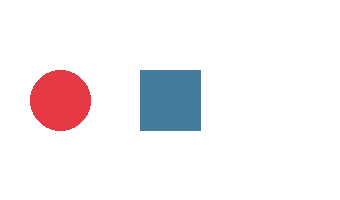

Рендерер работает.
Палитра: {'red': (230, 57, 70), 'blue': (69, 123, 157), 'green': (42, 157, 143), 'yellow': (233, 196, 106), 'purple': (131, 56, 236), 'orange': (244, 162, 97)}


In [2]:

from pathlib import Path
from PIL import Image, ImageDraw

# Единая палитра RGB для всех трёх этапов
PALETTE = {
    "red": (230, 57, 70),
    "blue": (69, 123, 157),
    "green": (42, 157, 143),
    "yellow": (233, 196, 106),
    "purple": (131, 56, 236),
    "orange": (244, 162, 97),
}

# Фиксированные позиции для 1–3 объектов.
# Каждая фигура занимает отдельную область изображения.
OBJECT_SLOTS = [
    (30, 70, 90, 130),
    (140, 70, 200, 130),
    (250, 70, 310, 130),
]

def render(objects, output_path=None, width=340, height=200):
    """
    Рисует список геометрических объектов без перекрытий.

    objects: список словарей вида
        {"shape": "circle", "color": "red"}

    Возвращает PIL RGB Image.
    """
    if not 1 <= len(objects) <= len(OBJECT_SLOTS):
        raise ValueError("Поддерживается от 1 до 3 объектов.")

    image = Image.new("RGB", (width, height), (255, 255, 255))
    draw = ImageDraw.Draw(image)

    for obj, (x1, y1, x2, y2) in zip(objects, OBJECT_SLOTS):
        shape = obj["shape"]
        color_name = obj["color"]

        if color_name not in PALETTE:
            raise ValueError(f"Неизвестный цвет: {color_name}")

        color = PALETTE[color_name]

        if shape == "circle":
            draw.ellipse((x1, y1, x2, y2), fill=color)
        elif shape == "square":
            draw.rectangle((x1, y1, x2, y2), fill=color)
        elif shape == "triangle":
            draw.polygon(
                [((x1 + x2) // 2, y1), (x1, y2), (x2, y2)],
                fill=color,
            )
        else:
            raise ValueError(f"Неизвестная форма: {shape}")

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        image.save(output_path, format="PNG")

    return image


# Проверяем рендерер
test_objects = [
    {"shape": "circle", "color": "red"},
    {"shape": "square", "color": "blue"},
]

test_image = render(test_objects)
display(test_image)

print("Рендерер работает.")
print("Палитра:", PALETTE)


### Пространство визуальных сцен

*Вес: 1 балл.*

**Постановка.** Этап «пространство визуальных сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сгенерируйте воспроизводимые сочетания формы, цвета и числа объектов.
2. Сохраните и предъявите воспроизводимые спецификации фигур и количества.

**Результат.** воспроизводимые спецификации фигур и количества.

**Критерий принятия.** Задание считается принятым, если воспроизводимые спецификации фигур и количества получены из фактических входов этого этапа и доступны для проверки.

In [3]:

import json
import random
from pathlib import Path

SEED = 42

SHAPES = ["circle", "square", "triangle"]
COLORS = list(PALETTE.keys())
OBJECT_COUNTS = [2, 3]

def generate_scene_specs(n=300, seed=SEED):
    """Создаёт воспроизводимые спецификации сцен."""
    if n < 1:
        raise ValueError("n должно быть не меньше 1.")

    rng = random.Random(seed)
    specs = []

    for i in range(n):
        count = rng.choice(OBJECT_COUNTS)

        objects = [
            {
                "shape": rng.choice(SHAPES),
                "color": rng.choice(COLORS),
            }
            for _ in range(count)
        ]

        specs.append({
            "scene_id": f"scene_{i:04d}",
            "seed": seed,
            "num_objects": count,
            "objects": objects,
        })

    return specs


scene_specs = generate_scene_specs(n=300, seed=SEED)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)

specs_path = ARTIFACTS / "scene_specs.json"
specs_path.write_text(
    json.dumps(scene_specs, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Проверяем воспроизводимость и корректность меток
assert scene_specs == generate_scene_specs(n=300, seed=SEED)

for spec in scene_specs:
    assert spec["num_objects"] == len(spec["objects"])
    assert 1 <= spec["num_objects"] <= 3
    assert all(obj["shape"] in SHAPES for obj in spec["objects"])
    assert all(obj["color"] in PALETTE for obj in spec["objects"])

print("Количество спецификаций:", len(scene_specs))
print("Файл:", specs_path)
print(json.dumps(scene_specs[:3], ensure_ascii=False, indent=2))


Количество спецификаций: 300
Файл: artifacts/scene_specs.json
[
  {
    "scene_id": "scene_0000",
    "seed": 42,
    "num_objects": 2,
    "objects": [
      {
        "shape": "circle",
        "color": "orange"
      },
      {
        "shape": "square",
        "color": "blue"
      }
    ]
  },
  {
    "scene_id": "scene_0001",
    "seed": 42,
    "num_objects": 2,
    "objects": [
      {
        "shape": "circle",
        "color": "orange"
      },
      {
        "shape": "circle",
        "color": "orange"
      }
    ]
  },
  {
    "scene_id": "scene_0002",
    "seed": 42,
    "num_objects": 2,
    "objects": [
      {
        "shape": "triangle",
        "color": "yellow"
      },
      {
        "shape": "circle",
        "color": "red"
      }
    ]
  }
]


### Изображения и вопросы

*Вес: 1 балл.*

**Постановка.** Этап «изображения и вопросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения, вопрос и ответ для каждой сцены.
2. Сохраните и предъявите файлы изображений и связанные с ними ответы.

**Результат.** файлы изображений и связанные с ними ответы.

**Критерий принятия.** Задание считается принятым, если файлы изображений и связанные с ними ответы получены из фактических входов этого этапа и доступны для проверки.

Создано изображений: 300
Папка изображений: artifacts/synthetic_images
Manifest: artifacts/synthetic_manifest.jsonl

Пример записи:
{
  "id": "scene_0000",
  "image": "/content/artifacts/synthetic_images/scene_0000.png",
  "question": "How many geometric shapes are visible in the image? Answer with one integer.",
  "answer": "2",
  "num_objects": 2,
  "objects": [
    {
      "shape": "circle",
      "color": "orange"
    },
    {
      "shape": "square",
      "color": "blue"
    }
  ],
  "source": "synthetic",
  "renderer": "render",
  "seed": 42
}


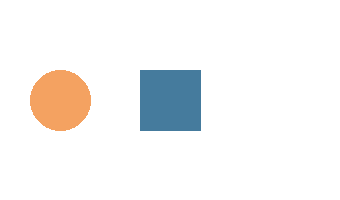

In [4]:

import json
from pathlib import Path
from PIL import Image

ARTIFACTS = Path("artifacts")
IMAGE_DIR = ARTIFACTS / "synthetic_images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

dataset = []

for spec in scene_specs:
    image_path = IMAGE_DIR / f"{spec['scene_id']}.png"

    # Рендерим именно объекты из спецификации
    image = render(
        objects=spec["objects"],
        output_path=image_path,
    )

    record = {
        "id": spec["scene_id"],
        "image": str(image_path.resolve()),
        "question": (
            "How many geometric shapes are visible in the image? "
            "Answer with one integer."
        ),
        "answer": str(spec["num_objects"]),
        "num_objects": spec["num_objects"],
        "objects": spec["objects"],
        "source": "synthetic",
        "renderer": "render",
        "seed": spec["seed"],
    }

    # Проверяем сохранённый файл
    with Image.open(image_path) as saved_image:
        saved_image.verify()

    dataset.append(record)

manifest_path = ARTIFACTS / "synthetic_manifest.jsonl"
manifest_path.write_text(
    "".join(
        json.dumps(row, ensure_ascii=False) + "\n"
        for row in dataset
    ),
    encoding="utf-8",
)

# Финальные проверки
assert len(dataset) == len(scene_specs)
assert all(Path(row["image"]).is_file() for row in dataset)
assert all(
    row["answer"] == str(len(row["objects"]))
    for row in dataset
)

print("Создано изображений:", len(dataset))
print("Папка изображений:", IMAGE_DIR)
print("Manifest:", manifest_path)
print("\nПример записи:")
print(json.dumps(dataset[0], ensure_ascii=False, indent=2))

display(Image.open(dataset[0]["image"]))


### Происхождение синтетических данных

*Вес: 1 балл.*

**Постановка.** Этап «происхождение синтетических данных» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Зафиксируйте seed, спецификацию, пути и provenance в манифесте.
2. Сохраните и предъявите artifacts/synthetic_manifest.jsonl.

**Результат.** artifacts/synthetic_manifest.jsonl.

**Критерий принятия.** Задание считается принятым, если artifacts/synthetic_manifest.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [5]:

import json
import hashlib
from pathlib import Path

ARTIFACTS = Path("artifacts")
IMAGE_DIR = ARTIFACTS / "synthetic_images"
MANIFEST_PATH = ARTIFACTS / "synthetic_manifest.jsonl"

assert "scene_specs" in globals(), (
    "Сначала выполни задание «Пространство визуальных сцен»."
)
assert "PALETTE" in globals(), (
    "Сначала выполни задание «Геометрический рендерер»."
)

ARTIFACTS.mkdir(parents=True, exist_ok=True)
manifest = []

for spec in scene_specs:
    image_path = IMAGE_DIR / f"{spec['scene_id']}.png"

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Нет изображения {image_path}. "
            "Сначала выполни задание «Изображения и вопросы»."
        )

    if spec["num_objects"] != len(spec["objects"]):
        raise ValueError(
            f"Некорректное количество объектов: {spec['scene_id']}"
        )

    # SHA-256 исходных байтов сохранённого изображения
    image_sha256 = hashlib.sha256(image_path.read_bytes()).hexdigest()

    record = {
        "id": spec["scene_id"],
        "source": "synthetic",
        "seed": spec["seed"],
        "specification": spec,
        "num_objects": spec["num_objects"],
        "question": (
            "How many geometric shapes are visible in the image? "
            "Answer with one integer."
        ),
        "answer": str(spec["num_objects"]),
        "image": str(image_path.resolve()),
        "image_relative_path": str(image_path),
        "image_sha256": image_sha256,
        "provenance": {
            "generator": "procedural_geometry_renderer",
            "renderer_function": "render",
            "palette": PALETTE,
            "coordinate_layout": OBJECT_SLOTS,
            "image_format": "PNG",
        },
    }

    manifest.append(record)

MANIFEST_PATH.write_text(
    "".join(
        json.dumps(row, ensure_ascii=False) + "\n"
        for row in manifest
    ),
    encoding="utf-8",
)

# Повторно читаем сохранённый файл и проверяем его
saved_records = [
    json.loads(line)
    for line in MANIFEST_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

assert len(saved_records) == len(scene_specs)
assert all(row["source"] == "synthetic" for row in saved_records)
assert all(len(row["image_sha256"]) == 64 for row in saved_records)

print("Манифест создан:", MANIFEST_PATH)
print("Количество записей:", len(saved_records))
print("\nПример provenance:")
print(json.dumps(saved_records[0], ensure_ascii=False, indent=2))


Манифест создан: artifacts/synthetic_manifest.jsonl
Количество записей: 300

Пример provenance:
{
  "id": "scene_0000",
  "source": "synthetic",
  "seed": 42,
  "specification": {
    "scene_id": "scene_0000",
    "seed": 42,
    "num_objects": 2,
    "objects": [
      {
        "shape": "circle",
        "color": "orange"
      },
      {
        "shape": "square",
        "color": "blue"
      }
    ]
  },
  "num_objects": 2,
  "question": "How many geometric shapes are visible in the image? Answer with one integer.",
  "answer": "2",
  "image": "/content/artifacts/synthetic_images/scene_0000.png",
  "image_relative_path": "artifacts/synthetic_images/scene_0000.png",
  "image_sha256": "5d00fb0c764f89eb8bdcb287d3e7ad32d22e5f69582e07b76d228bb7e593953a",
  "provenance": {
    "generator": "procedural_geometry_renderer",
    "renderer_function": "render",
    "palette": {
      "red": [
        230,
        57,
        70
      ],
      "blue": [
        69,
        123,
        157
   

### Ответы VLM и визуальная дедупликация

*Вес: 1 балл.*

**Постановка.** Этап «ответы vlm и визуальная дедупликация» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Спросите реальную VLM о числе фигур и найдите дубли по хешу пикселей.
2. Сохраните и предъявите artifacts/verification.jsonl с реальными ответами VLM.

**Результат.** artifacts/verification.jsonl с реальными ответами VLM.

**Критерий принятия.** Задание считается принятым, если artifacts/verification.jsonl с реальными ответами VLM получены из фактических входов этого этапа и доступны для проверки.

In [3]:
!pip install -U "bitsandbytes>=0.46.1"

In [6]:

import json
import hashlib
import re
from pathlib import Path
from PIL import Image

ARTIFACTS = Path("artifacts")
MANIFEST_PATH = ARTIFACTS / "synthetic_manifest.jsonl"
VERIFICATION_PATH = ARTIFACTS / "verification.jsonl"

assert MANIFEST_PATH.is_file(), (
    "Сначала выполни задание «Происхождение синтетических данных»."
)

# VLM_LOADER хранит код загрузчика в виде строки.
# Выполняем его только в том случае, если функция инференса
# ещё не создана предыдущими ячейками.
if "infer_image" not in globals():
    if "VLM_LOADER" not in globals():
        raise RuntimeError(
            "Не найдена переменная VLM_LOADER. "
            "Выполни исходную ячейку с загрузчиком."
        )
    exec(VLM_LOADER, globals())

assert "infer_image" in globals(), "Функция infer_image не определена."

records = [
    json.loads(line)
    for line in MANIFEST_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

# Вопрос просит только подсчитать фигуры.
PROMPT = (
    "Count all visible geometric shapes in this image. "
    "Count each circle, square, and triangle exactly once. "
    "Answer with one integer only."
)

# Хешируем именно декодированные пиксели RGB:
# одинаковые пиксели дадут одинаковый хеш независимо от метаданных PNG.
def pixel_sha256(image_path):
    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        payload = (
            str(rgb.size).encode("utf-8")
            + b"|"
            + rgb.tobytes()
        )
    return hashlib.sha256(payload).hexdigest()


def parse_count(answer_text):
    """Извлекает целочисленный ответ; None, если он неоднозначен."""
    text = answer_text.strip()
    match = re.fullmatch(
        r"(?:there are\s+|count:\s*)?(\d+)[.!]?",
        text,
        flags=re.IGNORECASE,
    )
    if match:
        return int(match.group(1))

    # Допускаем ответы вроде "There are 3 shapes."
    match = re.search(
        r"\b(?:there are|count is|answer is)\s+(\d+)\b",
        text,
        flags=re.IGNORECASE,
    )
    if match:
        return int(match.group(1))

    # Не угадываем число из произвольного объяснения.
    return None


# Первый встретившийся экземпляр каждого хеша становится оригиналом.
first_by_hash = {}
verified_count = 0

# Записываем построчно, чтобы частичный результат сохранился
# даже при прерывании долгого инференса.
with VERIFICATION_PATH.open("w", encoding="utf-8") as output_file:
    for index, record in enumerate(records, start=1):
        image_path = Path(record["image"])

        if not image_path.is_file():
            raise FileNotFoundError(f"Не найден файл: {image_path}")

        digest = pixel_sha256(image_path)

        duplicate_of = first_by_hash.get(digest)
        is_duplicate = duplicate_of is not None

        if not is_duplicate:
            first_by_hash[digest] = record["id"]

        # Реальный ответ модели, не эталонная метка.
        vlm_answer = infer_image(str(image_path), PROMPT)
        predicted_count = parse_count(vlm_answer)
        expected_count = int(record["answer"])

        result = {
            "id": record["id"],
            "image": str(image_path.resolve()),
            "source": record["source"],
            "question": PROMPT,
            "ground_truth": expected_count,
            "vlm_answer": vlm_answer,
            "predicted_count": predicted_count,
            "correct": (
                predicted_count == expected_count
                if predicted_count is not None
                else False
            ),
            "pixel_sha256": digest,
            "is_duplicate": is_duplicate,
            "duplicate_of": duplicate_of,
            "verification_model": globals().get("MODEL_ID", "unknown"),
        }

        output_file.write(
            json.dumps(result, ensure_ascii=False) + "\n"
        )
        output_file.flush()
        verified_count += 1

        print(
            f"[{index}/{len(records)}] {record['id']}: "
            f"GT={expected_count}, VLM={vlm_answer!r}, "
            f"duplicate={is_duplicate}"
        )

# Проверяем фактически записанный артефакт.
results = [
    json.loads(line)
    for line in VERIFICATION_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

assert len(results) == verified_count

print("\nПроверка завершена.")
print("Обработано изображений:", verified_count)
print("Найдено дубликатов:", sum(r["is_duplicate"] for r in results))
print("Правильных ответов VLM:", sum(r["correct"] for r in results))
print("Ответы без распознанного целого числа:",
      sum(r["predicted_count"] is None for r in results))
print("Результат:", VERIFICATION_PATH)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/3.53G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


[1/300] scene_0000: GT=2, VLM='2', duplicate=False
[2/300] scene_0001: GT=2, VLM='2', duplicate=False
[3/300] scene_0002: GT=2, VLM='2', duplicate=False
[4/300] scene_0003: GT=2, VLM='2', duplicate=False
[5/300] scene_0004: GT=2, VLM='2', duplicate=False
[6/300] scene_0005: GT=3, VLM='3', duplicate=False
[7/300] scene_0006: GT=3, VLM='2', duplicate=False
[8/300] scene_0007: GT=2, VLM='2', duplicate=False
[9/300] scene_0008: GT=3, VLM='3', duplicate=False
[10/300] scene_0009: GT=2, VLM='2', duplicate=False
[11/300] scene_0010: GT=3, VLM='3', duplicate=False
[12/300] scene_0011: GT=2, VLM='2', duplicate=False
[13/300] scene_0012: GT=3, VLM='3', duplicate=False
[14/300] scene_0013: GT=3, VLM='3', duplicate=False
[15/300] scene_0014: GT=2, VLM='2', duplicate=False
[16/300] scene_0015: GT=2, VLM='2', duplicate=False
[17/300] scene_0016: GT=2, VLM='2', duplicate=False
[18/300] scene_0017: GT=2, VLM='2', duplicate=False
[19/300] scene_0018: GT=2, VLM='2', duplicate=False
[20/300] scene_0019: 

### Отбор согласованных пар

*Вес: 1 балл.*

**Постановка.** Этап «отбор согласованных пар» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Отберите только изображения с согласованным ответом и без дублей.
2. Сохраните и предъявите artifacts/accepted.jsonl после проверки ответов.

**Результат.** artifacts/accepted.jsonl после проверки ответов.

**Критерий принятия.** Задание считается принятым, если artifacts/accepted.jsonl после проверки ответов получены из фактических входов этого этапа и доступны для проверки.

In [7]:

import json
from pathlib import Path

ARTIFACTS = Path("artifacts")
VERIFICATION_PATH = ARTIFACTS / "verification.jsonl"
ACCEPTED_PATH = ARTIFACTS / "accepted.jsonl"

# Проверяем, что предыдущий этап действительно создал входной файл.
if not VERIFICATION_PATH.is_file():
    raise FileNotFoundError(
        f"Не найден {VERIFICATION_PATH}. "
        "Сначала выполни этап проверки ответов VLM."
    )

with VERIFICATION_PATH.open("r", encoding="utf-8") as f:
    verification_records = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

accepted = []
rejected_incorrect = 0
rejected_duplicates = 0
rejected_unparsed = 0

# Принимаем только правильные, уникальные изображения.
seen_hashes = set()

for record in verification_records:
    # Не принимаем ответы, которые не удалось распознать как число.
    predicted = record.get("predicted_count")
    if predicted is None:
        rejected_unparsed += 1
        continue

    # Ответ модели должен совпадать с эталонным ответом.
    if not record.get("correct", False):
        rejected_incorrect += 1
        continue

    # Дубликаты выявляются по хешу пикселей.
    pixel_hash = record.get("pixel_sha256")
    if not pixel_hash:
        raise ValueError(
            f"У записи {record.get('id')} отсутствует pixel_sha256."
        )

    if record.get("is_duplicate", False) or pixel_hash in seen_hashes:
        rejected_duplicates += 1
        continue

    seen_hashes.add(pixel_hash)

    accepted.append({
        "id": record["id"],
        "image": record["image"],
        "source": record["source"],
        "question": record["question"],
        "answer": str(record["ground_truth"]),
        "predicted_count": predicted,
        "correct": True,
        "pixel_sha256": pixel_hash,
        "verification_model": record.get(
            "verification_model", "unknown"
        ),
    })

# Сохраняем итоговый набор в формате JSONL.
with ACCEPTED_PATH.open("w", encoding="utf-8") as f:
    for record in accepted:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

# Повторно читаем сохранённый файл и проверяем результат.
with ACCEPTED_PATH.open("r", encoding="utf-8") as f:
    saved_accepted = [
        json.loads(line)
        for line in f
        if line.strip()
    ]

assert len(saved_accepted) == len(accepted)
assert all(record["correct"] for record in saved_accepted)
assert len({
    record["pixel_sha256"] for record in saved_accepted
}) == len(saved_accepted)

print(f"Всего проверено: {len(verification_records)}")
print(f"Принято: {len(saved_accepted)}")
print(f"Отклонено — неверный ответ: {rejected_incorrect}")
print(f"Отклонено — неразобранный ответ: {rejected_unparsed}")
print(f"Отклонено — дубликат: {rejected_duplicates}")
print(f"Файл результата: {ACCEPTED_PATH.resolve()}")
print("\nПервые принятые записи:")
for record in saved_accepted[:2]:
    print(json.dumps(record, ensure_ascii=False, indent=2))


Всего проверено: 300
Принято: 265
Отклонено — неверный ответ: 5
Отклонено — неразобранный ответ: 0
Отклонено — дубликат: 30
Файл результата: /content/artifacts/accepted.jsonl

Первые принятые записи:
{
  "id": "scene_0000",
  "image": "/content/artifacts/synthetic_images/scene_0000.png",
  "source": "synthetic",
  "question": "Count all visible geometric shapes in this image. Count each circle, square, and triangle exactly once. Answer with one integer only.",
  "answer": "2",
  "predicted_count": 2,
  "correct": true,
  "pixel_sha256": "3fe8cdda39120e32eecbf1df7550ed9e1d3f949d10cfe7190004f633962abb10",
  "verification_model": "Qwen/Qwen2.5-VL-3B-Instruct"
}
{
  "id": "scene_0001",
  "image": "/content/artifacts/synthetic_images/scene_0001.png",
  "source": "synthetic",
  "question": "Count all visible geometric shapes in this image. Count each circle, square, and triangle exactly once. Answer with one integer only.",
  "answer": "2",
  "predicted_count": 2,
  "correct": true,
  "pixel

### Независимый набор реальных изображений

*Вес: 1 балл.*

**Постановка.** Этап «независимый набор реальных изображений» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Скачайте PixMo-Count validation для обучения и официальный test для отложенной оценки; проверьте метки и отсутствие общих ID/изображений.
2. Сохраните и предъявите проверенный real train/test manifest с источником, split и контрольными суммами.

**Результат.** проверенный real train/test manifest с источником, split и контрольными суммами.

**Критерий принятия.** Задание считается принятым, если проверенный real train/test manifest получены из фактических входов этого этапа и доступны для проверки.

In [15]:

import json
import hashlib
from pathlib import Path
from collections import Counter
from PIL import Image

# Скрипт open_real_scenes.py должен быть загружен в Colab.
from open_real_scenes import load_real_scenes

ROOT = Path("data/lab12")
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Загружаем реальные изображения:
# PixMo-Count validation -> train для эксперимента,
# официальный PixMo-Count test -> отложенная оценка.
real_records = load_real_scenes(
    root=str(ROOT),
    train_size=110,
    test_size=30,
)

manifest_path = ROOT / "real_manifest.jsonl"
if not manifest_path.is_file():
    raise FileNotFoundError(
        f"Скрипт не создал ожидаемый файл: {manifest_path}"
    )

with manifest_path.open("r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

if not records:
    raise ValueError("Реальный manifest пуст.")

def get_role(record):
    """Определяет экспериментальную роль записи."""
    role = str(record.get("split", "")).lower()
    source_split = str(record.get("source_split", "")).lower()

    if role in {"train", "test"}:
        return role
    if role in {"validation", "valid", "val"}:
        return "train"
    if source_split in {"validation", "valid", "val"}:
        return "train"
    if source_split == "test":
        return "test"

    raise ValueError(
        f"Не удалось определить split для записи {record.get('id')}: "
        f"split={role!r}, source_split={source_split!r}"
    )

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

checked_records = []
seen_ids = {"train": set(), "test": set()}
seen_source_rows = {"train": set(), "test": set()}
seen_source_hashes = {"train": set(), "test": set()}
seen_file_hashes = {"train": set(), "test": set()}
label_counts = {"train": Counter(), "test": Counter()}

for record in records:
    role = get_role(record)
    image_path = Path(record["image"])

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Не найдено изображение: {image_path}"
        )

    # Проверяем, что изображение действительно открывается.
    with Image.open(image_path) as image:
        image.verify()

    # Проверяем, что метка — целое число.
    answer = record.get("answer", record.get("count"))
    try:
        count = int(answer)
    except (TypeError, ValueError):
        raise ValueError(
            f"Некорректная метка у записи {record.get('id')}: {answer!r}"
        )

    if str(answer).strip() not in {str(count), f"{count}.0"}:
        raise ValueError(
            f"Метка не является целым числом: {answer!r}"
        )

    # Этот учебный набор должен содержать примеры с count=2 и count=3.
    if count not in (2, 3):
        raise ValueError(
            f"Неожиданная метка {count} у записи {record.get('id')}"
        )

    actual_file_hash = file_sha256(image_path)

    # Если скрипт сохранил хеш скачанного файла, сверяем его.
    expected_file_hash = record.get("downloaded_sha256")
    if expected_file_hash and actual_file_hash != expected_file_hash:
        raise ValueError(
            f"Контрольная сумма файла не совпала: {image_path}"
        )

    record_id = str(record.get("id", ""))
    if not record_id:
        raise ValueError(f"У записи отсутствует id: {image_path}")

    if record_id in seen_ids[role]:
        raise ValueError(
            f"Повторяющийся ID внутри split={role}: {record_id}"
        )
    seen_ids[role].add(record_id)

    # Проверяем ID исходной строки, если он сохранён.
    source_row = record.get("source_row")
    source_split = str(
        record.get("source_split", record.get("original_split", "unknown"))
    ).lower()

    if source_row is not None:
        # Номер строки уникален только в контексте исходного split.
        source_key = (source_split, str(source_row))

        if source_key in seen_source_rows[role]:
            raise ValueError(
                f"Повторяющаяся исходная строка в {role}: {source_key}"
            )

        seen_source_rows[role].add(source_key)

    # image_sha256 может быть хешем оригинала из метаданных источника.
    source_hash = record.get("image_sha256")
    if source_hash:
        seen_source_hashes[role].add(source_hash)

    seen_file_hashes[role].add(actual_file_hash)
    label_counts[role][count] += 1

    checked = dict(record)
    checked["split"] = role
    checked["answer"] = str(count)
    checked["local_file_sha256"] = actual_file_hash
    checked["manifest_verified"] = True
    checked_records.append(checked)

# Не допускаем пересечения train и test по ID, исходным строкам,
# хешам изображений из источника и фактическим файлам.
assert seen_ids["train"].isdisjoint(seen_ids["test"]), \
    "Обнаружено пересечение ID между train и test."
assert seen_source_rows["train"].isdisjoint(seen_source_rows["test"]), \
    "Обнаружено пересечение исходных строк между train и test."
assert seen_source_hashes["train"].isdisjoint(seen_source_hashes["test"]), \
    "Обнаружены одинаковые хеши исходных изображений между train и test."
assert seen_file_hashes["train"].isdisjoint(seen_file_hashes["test"]), \
    "Обнаружены одинаковые локальные изображения между train и test."

# Создаём общий проверенный manifest и отдельные файлы для удобства проверки.
combined_path = ARTIFACTS / "real_manifest_verified.jsonl"
train_path = ARTIFACTS / "real_train.jsonl"
test_path = ARTIFACTS / "real_test.jsonl"

def write_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

train_records = [r for r in checked_records if r["split"] == "train"]
test_records = [r for r in checked_records if r["split"] == "test"]

if not train_records or not test_records:
    raise ValueError(
        "Одна из выборок пустая. Проверь split в open_real_scenes.py."
    )

write_jsonl(combined_path, checked_records)
write_jsonl(train_path, train_records)
write_jsonl(test_path, test_records)

# Повторно читаем артефакты с диска и проверяем их содержимое.
def read_jsonl(path):
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

saved_all = read_jsonl(combined_path)
saved_train = read_jsonl(train_path)
saved_test = read_jsonl(test_path)

assert len(saved_all) == len(saved_train) + len(saved_test)
assert all(r["manifest_verified"] for r in saved_all)
assert all(r["split"] == "train" for r in saved_train)
assert all(r["split"] == "test" for r in saved_test)
assert all(Path(r["image"]).is_file() for r in saved_all)
assert all(len(r["local_file_sha256"]) == 64 for r in saved_all)

print("Проверка реального датасета завершена.")
print(f"Всего записей: {len(saved_all)}")
print(f"Train (PixMo-Count validation): {len(saved_train)}")
print(f"Test (официальный PixMo-Count test): {len(saved_test)}")
print(f"Метки train: {dict(label_counts['train'])}")
print(f"Метки test: {dict(label_counts['test'])}")
print(f"Общий manifest: {combined_path.resolve()}")
print(f"Train manifest: {train_path.resolve()}")
print(f"Test manifest: {test_path.resolve()}")



Loading train from PixMo-Count validation...
API error (1/7): 502 Server Error: Bad Gateway for url: https://datasets-server.huggingface.co/rows?dataset=allenai%2Fpixmo-count&config=default&split=validation&offset=0&length=100. Retry in 1.7s
validation: metadata rows fetched 100 (offset 0)
validation: metadata rows fetched 200 (offset 100)
validation: metadata rows fetched 300 (offset 200)
validation: metadata rows fetched 400 (offset 300)
validation: metadata rows fetched 500 (offset 400)
validation: metadata rows fetched 540 (offset 500)
  accepted 1/110: count=2, class totals={2: 1, 3: 0}
  accepted 2/110: count=2, class totals={2: 2, 3: 0}
  accepted 3/110: count=2, class totals={2: 3, 3: 0}
  accepted 4/110: count=2, class totals={2: 4, 3: 0}
  accepted 5/110: count=3, class totals={2: 4, 3: 1}
  accepted 6/110: count=3, class totals={2: 4, 3: 2}
  accepted 7/110: count=2, class totals={2: 5, 3: 2}
  accepted 8/110: count=3, class totals={2: 5, 3: 3}
  accepted 9/110: count=3, cl

### Признаки реальных и синтетических сцен

*Вес: 1 балл.*

**Постановка.** Этап «признаки реальных и синтетических сцен» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите одинаковые замороженные признаки ResNet18 для real train, synthetic и real test.
2. Сохраните и предъявите замороженные признаки ResNet18 для трёх наборов.

**Результат.** замороженные признаки ResNet18 для трёх наборов.

**Критерий принятия.** Задание считается принятым, если замороженные признаки ResNet18 для трёх наборов получены из фактических входов этого этапа и доступны для проверки.

In [16]:

import json
import hashlib
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

ARTIFACTS = Path("artifacts")
FEATURE_DIR = ARTIFACTS / "resnet18_features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Загружаем три набора из предыдущих этапов.
manifest_paths = {
    "real_train": ARTIFACTS / "real_train.jsonl",
    "synthetic": ARTIFACTS / "accepted.jsonl",
    "real_test": ARTIFACTS / "real_test.jsonl",
}

def read_jsonl(path):
    if not path.is_file():
        raise FileNotFoundError(
            f"Не найден {path}. Сначала выполни предыдущие этапы."
        )
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

manifests = {
    name: read_jsonl(path)
    for name, path in manifest_paths.items()
}

for name, rows in manifests.items():
    if not rows:
        raise ValueError(f"Набор {name} пуст.")
    for row in rows:
        if not Path(row["image"]).is_file():
            raise FileNotFoundError(
                f"Не найдено изображение набора {name}: {row['image']}"
            )

# 2. Одинаковая предобработка для всех трёх наборов.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = models.ResNet18_Weights.DEFAULT
preprocess = weights.transforms()

# Используем предобученные веса ImageNet, классификационную голову удаляем.
resnet = models.resnet18(weights=weights)
encoder = torch.nn.Sequential(*list(resnet.children())[:-1])
encoder.eval().to(device)

# Замораживаем параметры явно.
for parameter in encoder.parameters():
    parameter.requires_grad = False

class ImageManifestDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with Image.open(record["image"]) as image:
            image = image.convert("RGB")
            tensor = self.transform(image)
        return tensor, index

# 3. Извлекаем признаки без градиентов.
def extract_features(records, batch_size=32):
    dataset = ImageManifestDataset(records, preprocess)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    feature_batches = []
    with torch.inference_mode():
        for images, _ in loader:
            images = images.to(device)
            features = encoder(images)
            features = features.flatten(start_dim=1)
            feature_batches.append(features.cpu().numpy())

    if not feature_batches:
        return np.empty((0, 512), dtype=np.float32)

    return np.concatenate(feature_batches, axis=0).astype(np.float32)

# 4. Сохраняем признаки, ID, пути и контрольные суммы.
summary = {}

for name, records in manifests.items():
    features = extract_features(records)

    assert features.shape == (len(records), 512), (
        f"Неожиданная форма признаков для {name}: {features.shape}"
    )
    assert np.isfinite(features).all(), (
        f"В признаках {name} обнаружены NaN или бесконечности."
    )

    ids = [
        str(row.get("id", f"{name}_{i:05d}"))
        for i, row in enumerate(records)
    ]
    image_paths = [str(Path(row["image"]).resolve()) for row in records]

    feature_path = FEATURE_DIR / f"{name}_features.npz"
    np.savez_compressed(
        feature_path,
        features=features,
        ids=np.asarray(ids),
        image_paths=np.asarray(image_paths),
        split=np.asarray(name),
        backbone=np.asarray("ResNet18"),
        weights=np.asarray("DEFAULT_ImageNet"),
        feature_dim=np.asarray(512),
    )

    file_sha256 = hashlib.sha256(feature_path.read_bytes()).hexdigest()

    summary[name] = {
        "split": name,
        "num_images": len(records),
        "feature_dim": int(features.shape[1]),
        "backbone": "ResNet18",
        "weights": "DEFAULT_ImageNet",
        "frozen": True,
        "feature_file": str(feature_path.resolve()),
        "feature_file_sha256": file_sha256,
    }

# 5. Записываем provenance и проверяем сохранённые артефакты.
metadata_path = FEATURE_DIR / "metadata.json"
metadata = {
    "backbone": "ResNet18",
    "weights": "DEFAULT_ImageNet",
    "feature_layer": "avgpool_before_fc",
    "feature_dim": 512,
    "frozen": True,
    "preprocessing": "ResNet18_Weights.DEFAULT.transforms()",
    "device": str(device),
    "datasets": summary,
}
metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for name, info in summary.items():
    saved = np.load(info["feature_file"])
    assert saved["features"].shape == (
        info["num_images"], 512
    )
    assert len(saved["ids"]) == info["num_images"]
    assert saved["backbone"].item() == "ResNet18"

print("Извлечение замороженных признаков завершено.")
print(f"Устройство: {device}")
for name, info in summary.items():
    print(
        f"{name}: N={info['num_images']}, "
        f"shape=({info['num_images']}, 512)"
    )
    print(f"  Файл: {info['feature_file']}")
    print(f"  SHA-256: {info['feature_file_sha256']}")

print(f"Метаданные: {metadata_path.resolve()}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Извлечение замороженных признаков завершено.
Устройство: cuda
real_train: N=110, shape=(110, 512)
  Файл: /content/artifacts/resnet18_features/real_train_features.npz
  SHA-256: f6c1f648336d7bc576d8e89a63d503e8961bcf8f784dfc9cebd6a1e39c0fdf6d
synthetic: N=265, shape=(265, 512)
  Файл: /content/artifacts/resnet18_features/synthetic_features.npz
  SHA-256: 32788d30e8b6d942cb8ac3aef7956dac5c31c564c254bde715596c0b4f1d5ac4
real_test: N=30, shape=(30, 512)
  Файл: /content/artifacts/resnet18_features/real_test_features.npz
  SHA-256: 1b550102ad33119741c33c7b1b452b5f2f9573c16b4b267136a3ffcc1474dc2a
Метаданные: /content/artifacts/resnet18_features/metadata.json


### Обучение на смесях

*Вес: 1 балл.*

**Постановка.** Этап «обучение на смесях» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. При постоянном бюджете train обучите классификаторы с четырьмя долями синтетики.
2. Сохраните и предъявите результаты классификаторов при четырёх долях синтетики.

**Результат.** результаты классификаторов при четырёх долях синтетики.

**Критерий принятия.** Задание считается принятым, если результаты классификаторов при четырёх долях синтетики получены из фактических входов этого этапа и доступны для проверки.

In [17]:

import json
from pathlib import Path

import numpy as np
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

ARTIFACTS = Path("artifacts")
FEATURE_DIR = ARTIFACTS / "resnet18_features"
MODEL_DIR = ARTIFACTS / "mixture_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
SYNTHETIC_FRACTIONS = [0.0, 0.25, 0.50, 0.75]


def load_features(name):
    path = FEATURE_DIR / f"{name}_features.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

    with np.load(path, allow_pickle=False) as data:
        X = data["features"].astype(np.float32)
        ids = data["ids"].astype(str)

    if X.ndim != 2 or X.shape[1] != 512:
        raise ValueError(f"Неверная форма признаков {name}: {X.shape}")
    if len(X) != len(ids) or not np.isfinite(X).all():
        raise ValueError(f"Некорректные признаки или ID: {name}")

    return X, ids


def read_jsonl(path):
    if not path.is_file():
        raise FileNotFoundError(f"Не найден manifest: {path}")
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def get_label(record):
    label = int(record.get("answer", record.get("count")))
    if label not in (2, 3):
        raise ValueError(
            f"Ожидалась метка 2 или 3, получено {label}: {record.get('id')}"
        )
    return label


def aligned_labels(records, ids, name):
    manifest_ids = [str(r["id"]) for r in records]
    if manifest_ids != list(ids):
        raise ValueError(f"ID или порядок записей не совпадают: {name}")
    return np.asarray([get_label(r) for r in records], dtype=np.int64)


X_real, real_ids = load_features("real_train")
X_syn, syn_ids = load_features("synthetic")

y_real = aligned_labels(
    read_jsonl(ARTIFACTS / "real_train.jsonl"),
    real_ids,
    "real_train",
)
y_syn = aligned_labels(
    read_jsonl(ARTIFACTS / "accepted.jsonl"),
    syn_ids,
    "synthetic",
)

assert set(real_ids).isdisjoint(set(syn_ids)), (
    "ID real_train и synthetic пересекаются."
)

train_budget = len(X_real)
if train_budget < 4:
    raise ValueError("Слишком мало реальных обучающих примеров.")

required_syn = int(round(train_budget * max(SYNTHETIC_FRACTIONS)))
if len(X_syn) < required_syn:
    raise ValueError(
        f"Для всех долей нужен синтетический набор минимум из "
        f"{required_syn} примеров; доступно {len(X_syn)}."
    )

rng = np.random.default_rng(SEED)
training_results = []

for fraction in SYNTHETIC_FRACTIONS:
    n_syn = int(round(train_budget * fraction))
    n_real = train_budget - n_syn

    real_idx = rng.permutation(len(X_real))[:n_real]
    syn_idx = rng.permutation(len(X_syn))[:n_syn]

    X_parts, y_parts = [], []

    if n_real:
        X_parts.append(X_real[real_idx])
        y_parts.append(y_real[real_idx])

    if n_syn:
        X_parts.append(X_syn[syn_idx])
        y_parts.append(y_syn[syn_idx])

    X_train = np.concatenate(X_parts, axis=0)
    y_train = np.concatenate(y_parts, axis=0)

    order = rng.permutation(len(y_train))
    X_train, y_train = X_train[order], y_train[order]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.01,
            max_iter=2000,
            class_weight=None,
            random_state=SEED,
        ),
    )
    model.fit(X_train, y_train)

    # Только обучающая выборка. Test на этом этапе не загружается.
    train_predictions = model.predict(X_train)
    train_accuracy = float(accuracy_score(y_train, train_predictions))

    model_path = MODEL_DIR / f"model_fraction_{fraction:.2f}.joblib"
    joblib.dump(model, model_path)

    training_results.append({
        "synthetic_fraction": fraction,
        "real_fraction": 1.0 - fraction,
        "train_budget": int(len(y_train)),
        "n_real_train": int(n_real),
        "n_synthetic_train": int(n_syn),
        "train_accuracy": train_accuracy,
        "model_path": str(model_path),
        "classifier": "StandardScaler + LogisticRegression",
        "feature_extractor": "Frozen ResNet18 ImageNet",
        "seed": SEED,
    })

training_path = ARTIFACTS / "mixture_training_results.json"
training_path.write_text(
    json.dumps(training_results, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

assert len(training_results) == 4
assert len({r["train_budget"] for r in training_results}) == 1

print("Обучение завершено. Test не использовался.")
print(f"Постоянный train-бюджет: {train_budget}")
print("Доля синтетики | Реальных | Синтетических | Train accuracy")

for r in training_results:
    print(
        f"{r['synthetic_fraction']:>14.0%} | "
        f"{r['n_real_train']:>8} | "
        f"{r['n_synthetic_train']:>13} | "
        f"{r['train_accuracy']:.4f}"
    )

print(f"\nРезультаты обучения: {training_path}")
print(f"Обученные модели: {MODEL_DIR}")


Обучение завершено. Test не использовался.
Постоянный train-бюджет: 110
Доля синтетики | Реальных | Синтетических | Train accuracy
            0% |      110 |             0 | 0.9727
           25% |       82 |            28 | 0.9455
           50% |       55 |            55 | 0.9909
           75% |       28 |            82 | 1.0000

Результаты обучения: artifacts/mixture_training_results.json
Обученные модели: artifacts/mixture_models


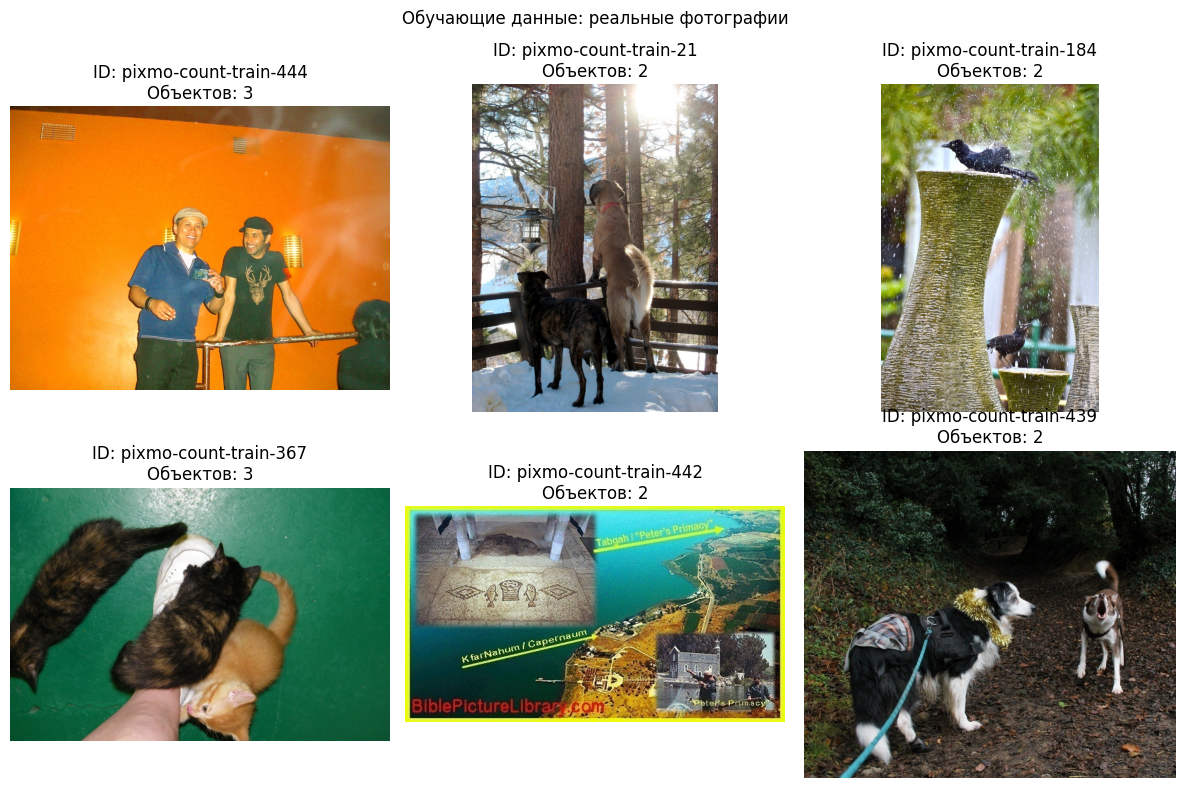

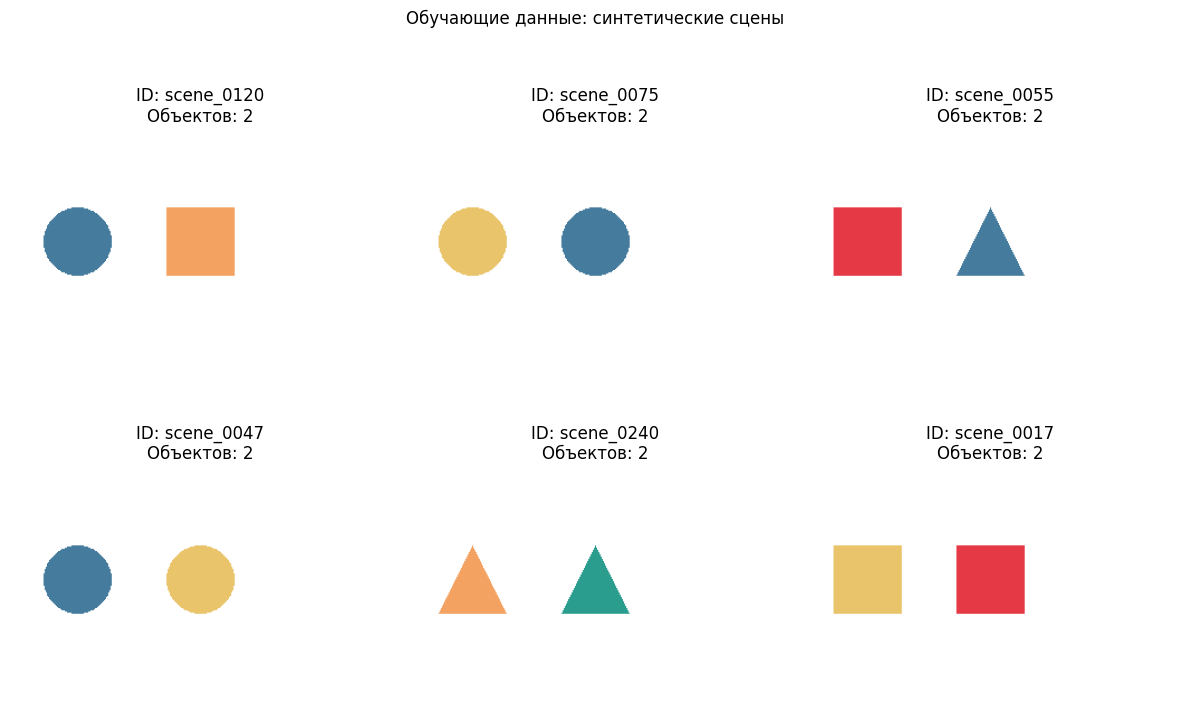

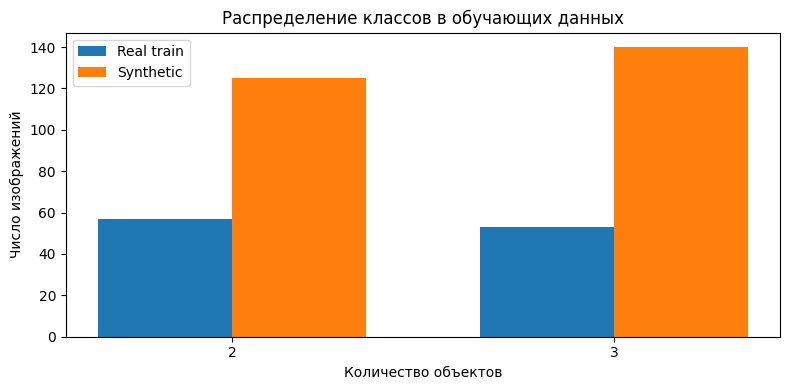

Реальных обучающих изображений: 110
Синтетических принятых изображений: 265


In [18]:

import json
import random
import math
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ARTIFACTS = Path("artifacts")

def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

real_train = read_jsonl(ARTIFACTS / "real_train.jsonl")
synthetic_train = read_jsonl(ARTIFACTS / "accepted.jsonl")

rng = random.Random(42)
n_show = 6

def get_count(record):
    return int(record.get("answer", record.get("num_objects", record.get("count"))))

def show_image_grid(records, title, n=6):
    if not records:
        print(f"{title}: набор пуст.")
        return

    selected = rng.sample(records, min(n, len(records)))
    cols = 3
    rows = math.ceil(len(selected) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax, record in zip(axes, selected):
        with Image.open(record["image"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(
            f"ID: {record.get('id', '?')}\n"
            f"Объектов: {get_count(record)}"
        )
        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_image_grid(real_train, "Обучающие данные: реальные фотографии", n_show)
show_image_grid(synthetic_train, "Обучающие данные: синтетические сцены", n_show)

# Сравним распределения классов.
real_counts = Counter(get_count(r) for r in real_train)
syn_counts = Counter(get_count(r) for r in synthetic_train)

classes = sorted(set(real_counts) | set(syn_counts))
x = list(range(len(classes)))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar([i - width / 2 for i in x],
        [real_counts[c] for c in classes],
        width, label="Real train")
plt.bar([i + width / 2 for i in x],
        [syn_counts[c] for c in classes],
        width, label="Synthetic")
plt.xticks(x, classes)
plt.xlabel("Количество объектов")
plt.ylabel("Число изображений")
plt.title("Распределение классов в обучающих данных")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Реальных обучающих изображений: {len(real_train)}")
print(f"Синтетических принятых изображений: {len(synthetic_train)}")


### Оценка на реальном тесте

*Вес: 1 балл.*

**Постановка.** Этап «оценка на реальном тесте» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Запишите предсказания и accuracy всех моделей только на реальном test.
2. Сохраните и предъявите mixture_results.json и predictions.jsonl.

**Результат.** mixture_results.json и predictions.jsonl.

**Критерий принятия.** Задание считается принятым, если mixture_results.json и predictions.jsonl получены из фактических входов этого этапа и доступны для проверки.

In [19]:

import json
from pathlib import Path

import numpy as np
import joblib
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ARTIFACTS = Path("artifacts")
FEATURE_DIR = ARTIFACTS / "resnet18_features"
MODEL_DIR = ARTIFACTS / "mixture_models"

def load_features(name):
    path = FEATURE_DIR / f"{name}_features.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Не найден файл: {path}")

    with np.load(path, allow_pickle=False) as data:
        X = data["features"].astype(np.float32)
        ids = data["ids"].astype(str)

    if X.ndim != 2 or X.shape[1] != 512:
        raise ValueError(f"Неверная форма признаков: {X.shape}")
    if len(X) != len(ids) or not np.isfinite(X).all():
        raise ValueError("Некорректные признаки или ID")

    return X, ids


def read_jsonl(path):
    if not path.is_file():
        raise FileNotFoundError(f"Не найден manifest: {path}")
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def get_label(record):
    label = int(record.get("answer", record.get("count")))
    if label not in (2, 3):
        raise ValueError(
            f"Ожидалась метка 2 или 3, получено {label}: {record.get('id')}"
        )
    return label


X_test, test_ids = load_features("real_test")
test_records = read_jsonl(ARTIFACTS / "real_test.jsonl")

if [str(r["id"]) for r in test_records] != list(test_ids):
    raise ValueError("ID или порядок real_test не совпадают с признаками")

y_test = np.asarray(
    [get_label(r) for r in test_records],
    dtype=np.int64,
)

training_path = ARTIFACTS / "mixture_training_results.json"
if not training_path.is_file():
    raise FileNotFoundError("Сначала выполни блок 1.")

training_results = json.loads(training_path.read_text(encoding="utf-8"))
if len(training_results) != 4:
    raise ValueError("В результатах обучения должно быть четыре модели")

mixture_results = []
prediction_records = []

for train_result in training_results:
    fraction = train_result["synthetic_fraction"]
    model_path = Path(train_result["model_path"])

    if not model_path.is_file():
        raise FileNotFoundError(f"Не найдена модель: {model_path}")

    model = joblib.load(model_path)

    # Оценка исключительно на реальном тестовом наборе.
    predictions = model.predict(X_test).astype(int)

    test_accuracy = float(accuracy_score(y_test, predictions))
    test_macro_f1 = float(
        f1_score(y_test, predictions, average="macro", zero_division=0)
    )
    cm = confusion_matrix(y_test, predictions, labels=[2, 3]).tolist()

    mixture_results.append({
        **train_result,
        "n_test": int(len(y_test)),
        "test_accuracy": test_accuracy,
        "macro_f1": test_macro_f1,
        "confusion_matrix_labels_2_3": cm,
    })

    for image_id, y_true, y_pred in zip(test_ids, y_test, predictions):
        prediction_records.append({
            "synthetic_fraction": fraction,
            "id": str(image_id),
            "y_true": int(y_true),
            "y_pred": int(y_pred),
            "correct": bool(y_true == y_pred),
        })

results_path = ARTIFACTS / "mixture_results.json"
results_path.write_text(
    json.dumps(mixture_results, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

predictions_path = ARTIFACTS / "predictions.jsonl"
with predictions_path.open("w", encoding="utf-8") as f:
    for record in prediction_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

assert len(mixture_results) == 4
assert len(prediction_records) == 4 * len(y_test)

print("Оценка на реальном test завершена.")
print(f"Размер real_test: {len(y_test)}")
print("Доля синтетики | Train accuracy | Test accuracy | Macro-F1")

for r in mixture_results:
    print(
        f"{r['synthetic_fraction']:>14.0%} | "
        f"{r['train_accuracy']:.4f} | "
        f"{r['test_accuracy']:.4f} | "
        f"{r['macro_f1']:.4f}"
    )

print(f"\nРезультаты моделей: {results_path}")
print(f"Предсказания: {predictions_path}")
print(f"Число записей predictions.jsonl: {len(prediction_records)}")


Оценка на реальном test завершена.
Размер real_test: 30
Доля синтетики | Train accuracy | Test accuracy | Macro-F1
            0% | 0.9727 | 0.5667 | 0.5543
           25% | 0.9455 | 0.3667 | 0.3486
           50% | 0.9909 | 0.5667 | 0.5662
           75% | 1.0000 | 0.5667 | 0.5238

Результаты моделей: artifacts/mixture_results.json
Предсказания: artifacts/predictions.jsonl
Число записей predictions.jsonl: 120


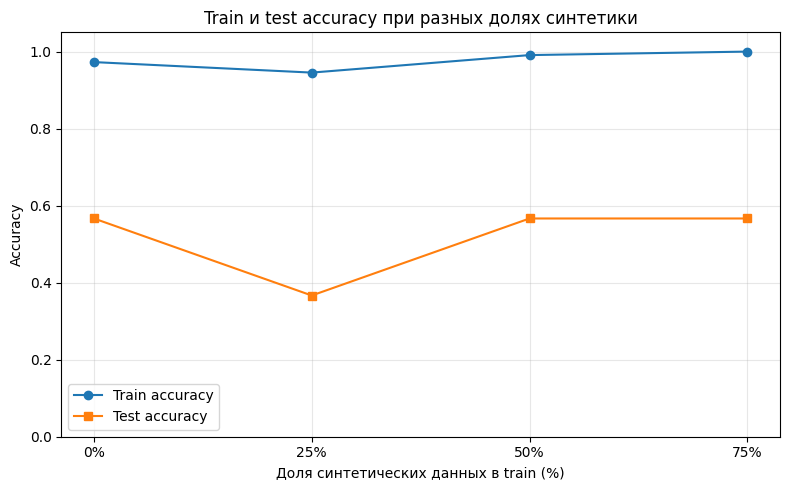

График сохранён: artifacts/accuracy_vs_synthetic_fraction.png


In [20]:

import json
from pathlib import Path
import matplotlib.pyplot as plt

ARTIFACTS = Path("artifacts")

training_results = json.loads(
    (ARTIFACTS / "mixture_training_results.json").read_text(
        encoding="utf-8"
    )
)
test_results = json.loads(
    (ARTIFACTS / "mixture_results.json").read_text(
        encoding="utf-8"
    )
)

# Сопоставляем результаты по доле синтетики.
train_by_fraction = {
    r["synthetic_fraction"]: r for r in training_results
}
test_by_fraction = {
    r["synthetic_fraction"]: r for r in test_results
}

fractions = sorted(train_by_fraction.keys())

if fractions != sorted(test_by_fraction.keys()):
    raise ValueError(
        "Наборы долей синтетики в результатах обучения и тестирования "
        "не совпадают."
    )

train_accuracy = [
    train_by_fraction[f]["train_accuracy"] for f in fractions
]
test_accuracy = [
    test_by_fraction[f]["test_accuracy"] for f in fractions
]

x = [f * 100 for f in fractions]

plt.figure(figsize=(8, 5))
plt.plot(x, train_accuracy, marker="o", label="Train accuracy")
plt.plot(x, test_accuracy, marker="s", label="Test accuracy")

plt.xlabel("Доля синтетических данных в train (%)")
plt.ylabel("Accuracy")
plt.title("Train и test accuracy при разных долях синтетики")
plt.xticks(x, [f"{v:.0f}%" for v in x])
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = ARTIFACTS / "accuracy_vs_synthetic_fraction.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"График сохранён: {plot_path}")


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [21]:

!pip -q install datasets requests pillow

from datasets import load_dataset
from pathlib import Path
from PIL import Image
from io import BytesIO
import requests
import random
import csv
import json
import hashlib

BASE = Path("/content/artifacts/bonus_data")
IMG_DIR = BASE / "images"
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Исключаем уже известные URL и хеши основного эксперимента.
excluded_urls = set()
excluded_hashes = set()

for manifest in [
    Path("/content/artifacts/real_train.jsonl"),
    Path("/content/artifacts/real_test.jsonl"),
    Path("/content/artifacts/accepted.jsonl"),
]:
    if manifest.exists():
        for line in manifest.read_text(encoding="utf-8").splitlines():
            try:
                r = json.loads(line)
                for key in ("image_url", "url"):
                    if r.get(key):
                        excluded_urls.add(str(r[key]))
                for key in ("image_sha256", "sha256"):
                    if r.get(key):
                        excluded_hashes.add(str(r[key]).lower())
            except Exception:
                pass

print("Загружаем метаданные PixMo-Count...")
ds = load_dataset("allenai/pixmo-count", split="train")

# Сначала пробуем случайную выборку, а не первые записи.
indices = list(range(len(ds)))
random.Random(42).shuffle(indices)

session = requests.Session()
session.headers.update({
    "User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 Chrome/124 Safari/537.36",
    "Referer": "https://www.flickr.com/",
})

records = []
seen_urls = set(excluded_urls)
seen_hashes = set(excluded_hashes)
counts = {2: 0, 3: 0}
TARGET = 25
errors = {}

for idx in indices:
    if counts[2] >= TARGET and counts[3] >= TARGET:
        break

    row = ds[int(idx)]
    count = int(row["count"])
    url = row["image_url"]

    if count not in (2, 3):
        continue
    if counts[count] >= TARGET:
        continue
    if not url or url in seen_urls:
        continue

    seen_urls.add(url)

    try:
        response = session.get(url, timeout=15)
        response.raise_for_status()

        image_bytes = response.content
        digest = hashlib.sha256(image_bytes).hexdigest()

        if digest in seen_hashes:
            continue

        # Не сохраняем HTML-страницы под видом изображений.
        image = Image.open(BytesIO(image_bytes)).convert("RGB")
        image.verify()

        image = Image.open(BytesIO(image_bytes)).convert("RGB")
        image_id = f"bonus_{idx:05d}"
        image_path = IMG_DIR / f"{image_id}.jpg"
        image.save(image_path, quality=95)

        seen_hashes.add(digest)
        records.append({
            "id": image_id,
            "source_index": int(idx),
            "image_sha256": digest,
            "count": count,
            "image_path": str(image_path),
            "image_url": url,
            "overlap": "",
            "count_verified": "",
            "notes": "",
        })
        counts[count] += 1
        print(f"OK {image_id}: count={count}; "
              f"итого 2: {counts[2]}, 3: {counts[3]}")

    except Exception as e:
        kind = f"{type(e).__name__}: {str(e)[:100]}"
        errors[kind] = errors.get(kind, 0) + 1
        continue

csv_path = BASE / "bonus_candidates_to_annotate.csv"

if records:
    with csv_path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(records[0].keys()))
        writer.writeheader()
        writer.writerows(records)

print("\nИТОГ")
print("Скачано:", len(records))
print("count=2:", counts[2])
print("count=3:", counts[3])
print("Ошибки загрузки:", errors)
print("Папка изображений:", IMG_DIR)
print("CSV:", csv_path if records else "не создан")

if len(records) == 0:
    print(
        "\nНи одно изображение не скачалось. "
        "Скопируй сюда вывод «Ошибки загрузки» — "
        "тогда подберём другой источник, а не будем "
        "повторять неработающий способ."
    )


Загружаем метаданные PixMo-Count...


README.md: 0.00B [00:00, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/59.2k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/5.12M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/59.0k [00:00<?, ?B/s]

Generating validation split:   0%|          | 0/540 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36916 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/540 [00:00<?, ? examples/s]

OK bonus_05602: count=3; итого 2: 0, 3: 1
OK bonus_22630: count=2; итого 2: 1, 3: 1
OK bonus_22736: count=2; итого 2: 2, 3: 1
OK bonus_00773: count=3; итого 2: 2, 3: 2
OK bonus_14142: count=3; итого 2: 2, 3: 3
OK bonus_22042: count=3; итого 2: 2, 3: 4
OK bonus_28793: count=2; итого 2: 3, 3: 4
OK bonus_12525: count=2; итого 2: 4, 3: 4
OK bonus_09465: count=2; итого 2: 5, 3: 4
OK bonus_20744: count=2; итого 2: 6, 3: 4
OK bonus_02566: count=2; итого 2: 7, 3: 4
OK bonus_02011: count=3; итого 2: 7, 3: 5
OK bonus_19687: count=2; итого 2: 8, 3: 5
OK bonus_08783: count=3; итого 2: 8, 3: 6
OK bonus_34774: count=3; итого 2: 8, 3: 7
OK bonus_35368: count=3; итого 2: 8, 3: 8
OK bonus_04247: count=3; итого 2: 8, 3: 9
OK bonus_03127: count=3; итого 2: 8, 3: 10
OK bonus_01597: count=3; итого 2: 8, 3: 11
OK bonus_09708: count=2; итого 2: 9, 3: 11
OK bonus_01415: count=2; итого 2: 10, 3: 11
OK bonus_20954: count=3; итого 2: 10, 3: 12
OK bonus_34075: count=2; итого 2: 11, 3: 12
OK bonus_35083: count=2; 

Всего изображений: 50
Изображения 1–12


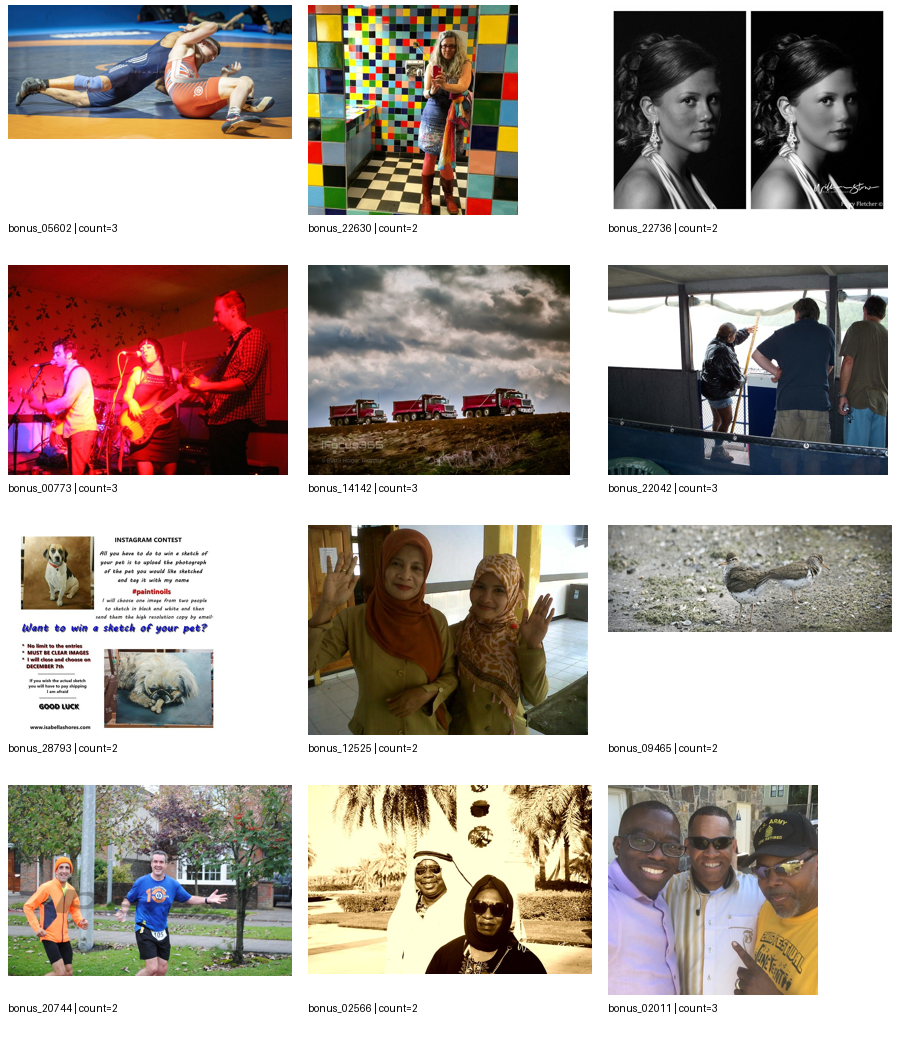

Изображения 13–24


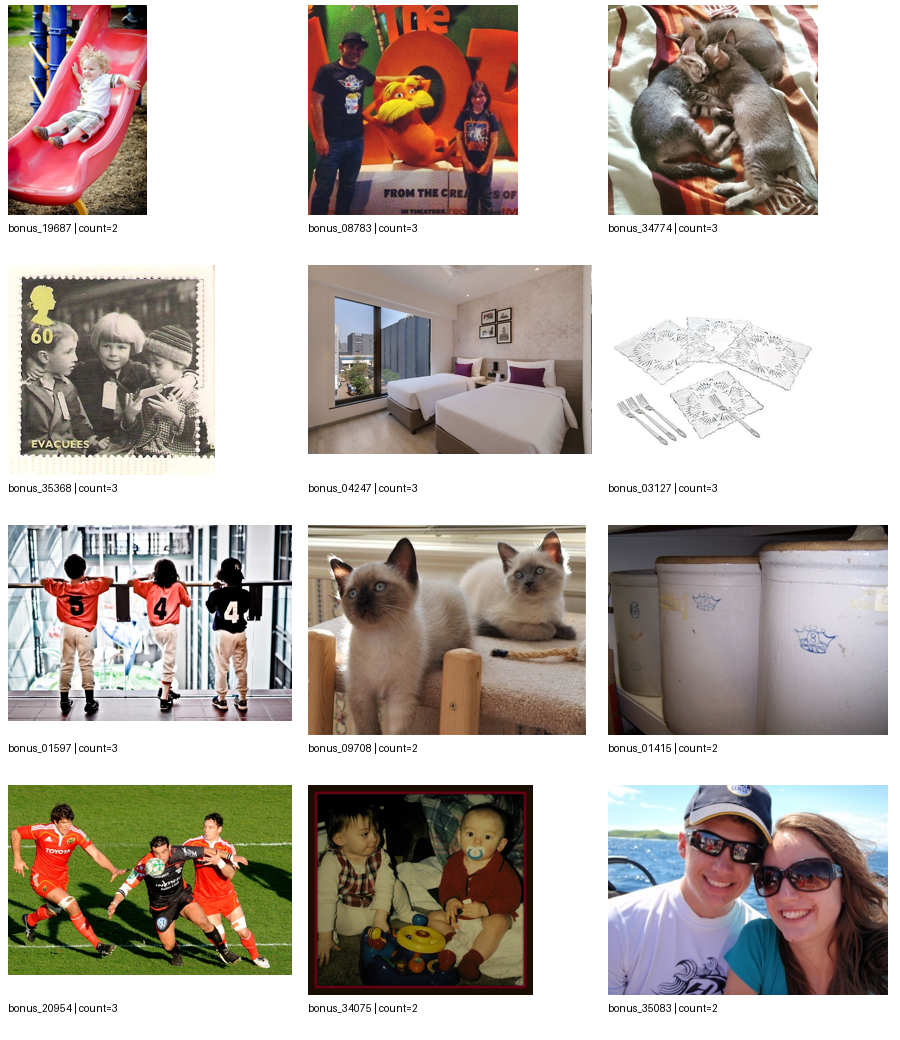

Изображения 25–36


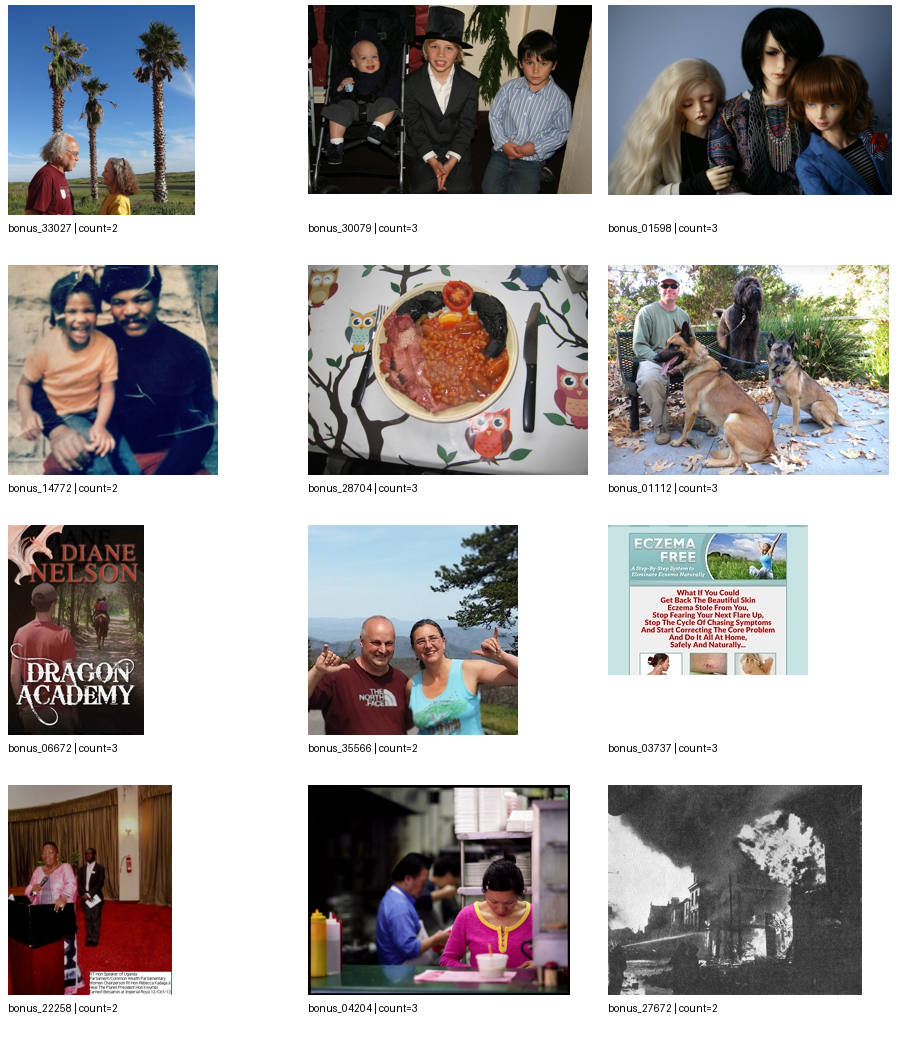

Изображения 37–48


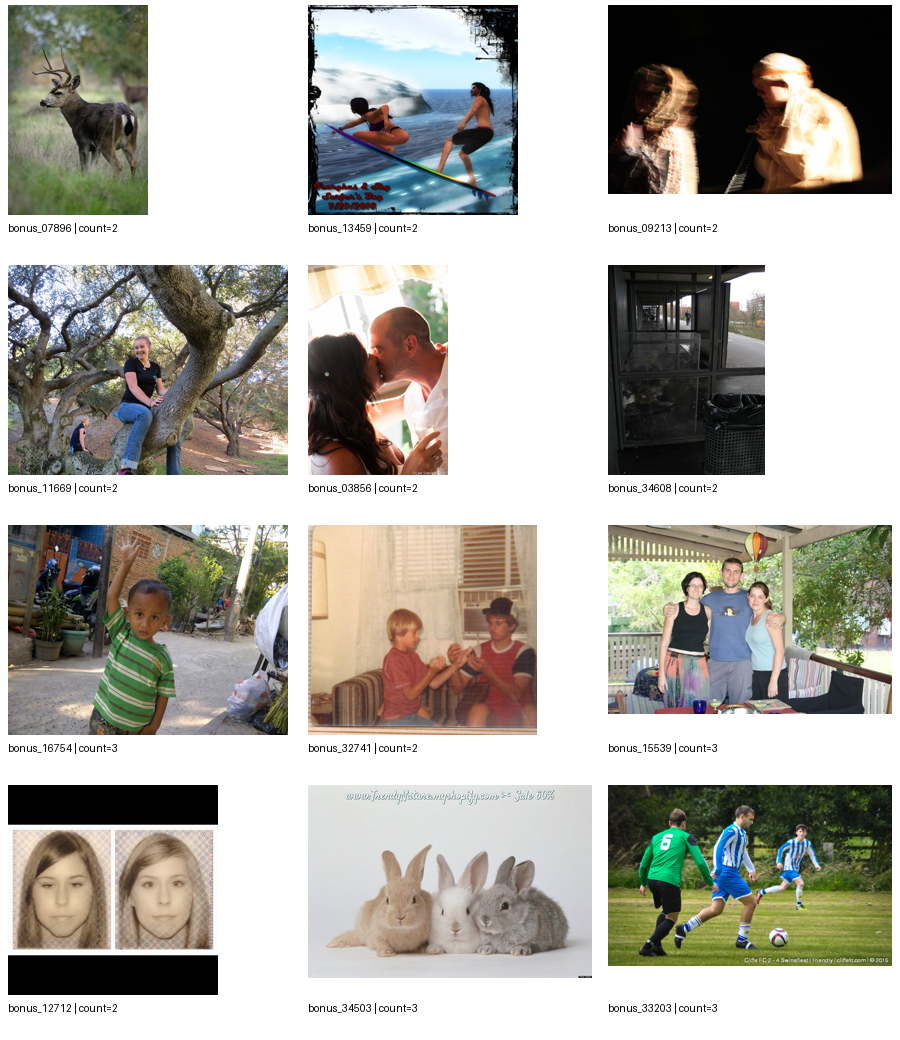

Изображения 49–50


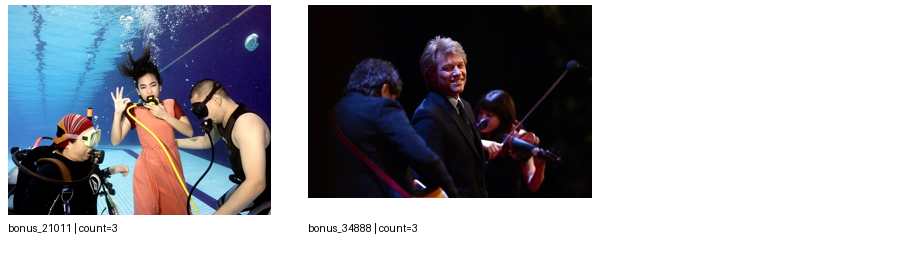

In [22]:

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import csv
import math

BASE = Path("/content/artifacts/bonus_data")
IMAGE_DIR = BASE / "images"
CSV_PATH = BASE / "bonus_candidates_to_annotate.csv"

with CSV_PATH.open(encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f))

print("Всего изображений:", len(rows))

# Показываем по 12 изображений за раз.
PAGE_SIZE = 12

for start in range(0, len(rows), PAGE_SIZE):
    batch = rows[start:start + PAGE_SIZE]
    cols = 3
    cell_w, cell_h = 300, 260
    sheet = Image.new(
        "RGB",
        (cols * cell_w, math.ceil(len(batch) / cols) * cell_h),
        "white"
    )
    draw = ImageDraw.Draw(sheet)

    for i, row in enumerate(batch):
        path = Path(row["image_path"])
        if not path.exists():
            continue

        img = Image.open(path).convert("RGB")
        img.thumbnail((cell_w - 16, cell_h - 50))

        x = (i % cols) * cell_w
        y = (i // cols) * cell_h
        sheet.paste(img, (x + 8, y + 5))

        draw.text(
            (x + 8, y + cell_h - 38),
            f"{row['id']} | count={row['count']}",
            fill="black"
        )

    print(f"Изображения {start + 1}–{start + len(batch)}")
    display(sheet)


In [ ]:

from pathlib import Path
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
from PIL import Image
import joblib

# ================== Configuration ==================
CSV_PATH = Path("artifacts/bonus_data/bonus_candidates_to_annotate.csv")
IMAGE_DIR = Path("artifacts/bonus_data/images")
MODEL_DIR = Path("artifacts/mixture_models")
FEATURE_DIR = Path("artifacts/resnet18_features")
PREDICTIONS_PATH = Path("artifacts/bonus_predictions.jsonl")
SUMMARY_PATH = Path("artifacts/bonus_summary.json")

# Use the mixture trained with 50% real data, if available.
MODEL_FRACTION = "0.50"

SEED = 42
N_BOOTSTRAP = 10000
N_PERMUTATIONS = 20000

# ================== Read annotations correctly ==================
if not CSV_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH.resolve()}")

if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR.resolve()}")

df = pd.read_csv(CSV_PATH, sep=";", dtype={"id": str})

required = {"id", "image_path", "overlap", "count_verified"}
missing = required - set(df.columns)
if missing:
    raise ValueError(
        f"Missing columns: {sorted(missing)}. "
        f"CSV columns after parsing: {df.columns.tolist()}"
    )

df["id"] = df["id"].astype(str).str.strip()
df["overlap"] = df["overlap"].astype(str).str.strip().str.lower()
df["count_verified"] = pd.to_numeric(
    df["count_verified"], errors="coerce"
)

def parse_overlap(value):
    if value in {"0", "0.0", "false", "no", "n", "non-overlap", "nonoverlap"}:
        return 0
    if value in {"1", "1.0", "true", "yes", "y", "overlap"}:
        return 1
    return np.nan

df["overlap_bin"] = df["overlap"].map(parse_overlap)

# Resolve paths robustly: prefer the actual local file with the annotated ID.
def resolve_image(row):
    image_id = row["id"]
    candidates = [
        IMAGE_DIR / f"{image_id}.jpg",
        IMAGE_DIR / f"{image_id}.jpeg",
        IMAGE_DIR / f"{image_id}.png",
        IMAGE_DIR / f"{image_id}.webp",
    ]

    raw_path = str(row.get("image_path", "")).strip()
    if raw_path and raw_path.lower() != "nan":
        p = Path(raw_path)
        candidates.extend([p, Path.cwd() / p])

    for p in candidates:
        if p.exists() and p.is_file():
            return p.resolve()

    return None

df["resolved_image"] = df.apply(resolve_image, axis=1)

bad = df[
    df["overlap_bin"].isna()
    | df["count_verified"].isna()
    | ~df["count_verified"].isin([2, 3])
    | df["resolved_image"].isna()
]

if len(bad):
    print("Rows excluded because of missing/invalid annotation or image:")
    display(bad[["id", "overlap", "count_verified", "image_path"]].head(20))

df = df[
    df["overlap_bin"].notna()
    & df["count_verified"].notna()
    & df["count_verified"].isin([2, 3])
    & df["resolved_image"].notna()
].copy()

df["overlap_bin"] = df["overlap_bin"].astype(int)
df["count_verified"] = df["count_verified"].astype(int)

if df["id"].duplicated().any():
    raise ValueError("Duplicate IDs in annotation CSV.")

if df.empty:
    raise ValueError("No valid annotated rows with accessible images.")

print(f"Valid annotated rows: {len(df)}")
print("Overlap group sizes:")
print(df["overlap_bin"].value_counts().sort_index().rename(
    index={0: "no overlap", 1: "overlap"}
))

# ================== Locate saved classifier ==================
model_path = MODEL_DIR / f"model_fraction_{MODEL_FRACTION}.joblib"

if not model_path.exists():
    available = sorted(MODEL_DIR.glob("*.joblib"))
    raise FileNotFoundError(
        f"Model not found: {model_path.resolve()}\n"
        f"Available model files: {[p.name for p in available]}\n"
        "Set MODEL_FRACTION to one of the existing model fractions."
    )

model = joblib.load(model_path)
print(f"\nLoaded model: {model_path.resolve()}")
print("Model type:", type(model).__name__)

# ================== Feature extraction ==================
# The saved models in this lab use ResNet18 image features.
# Reuse the notebook's saved feature extractor if available; otherwise
# create a standard pretrained ResNet18 extractor.
try:
    import torch
    from torchvision import models, transforms

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    weights = models.ResNet18_Weights.DEFAULT
    backbone = models.resnet18(weights=weights)
    backbone.fc = torch.nn.Identity()
    backbone = backbone.to(device).eval()

    transform = weights.transforms()

    features = []
    valid_records = []

    with torch.no_grad():
        for _, row in df.iterrows():
            image_path = Path(row["resolved_image"])
            try:
                with Image.open(image_path) as im:
                    image = im.convert("RGB")
                    tensor = transform(image).unsqueeze(0).to(device)

                vector = backbone(tensor).squeeze(0).cpu().numpy()
                features.append(vector)
                valid_records.append(row.to_dict())

            except Exception as exc:
                print(f"Skipping unreadable image {image_path.name}: {exc}")

    if not features:
        raise RuntimeError("No valid image features could be extracted.")

    X = np.stack(features).astype(np.float32)
    eval_df = pd.DataFrame(valid_records).reset_index(drop=True)

except Exception as exc:
    raise RuntimeError(
        "Could not extract ResNet18 features. "
        "Check that torch/torchvision are installed and that the pretrained "
        "ResNet18 weights are available in this Colab runtime. "
        f"Original error: {exc}"
    ) from exc

# ================== Predict ==================
# Do not train or tune the model on these bonus examples.
if not hasattr(model, "predict"):
    raise TypeError(
        f"Loaded object {type(model).__name__} has no predict() method. "
        "Inspect the saved training code: the artifact may be a dict or "
        "pipeline with a different inference interface."
    )

pred_raw = np.asarray(model.predict(X)).reshape(-1)

def parse_prediction(value):
    try:
        number = float(value)
        if number.is_integer():
            return int(number)
    except (TypeError, ValueError):
        pass
    return None

predictions = [parse_prediction(x) for x in pred_raw]
eval_df["prediction"] = predictions
eval_df["correct"] = (
    eval_df["prediction"] == eval_df["count_verified"]
).astype(int)

# Keep only rows where the model predicted a valid class.
eval_df = eval_df[eval_df["prediction"].isin([2, 3])].copy()

if eval_df.empty:
    raise RuntimeError(
        "The model did not produce any predictions in classes 2/3. "
        "Check the classifier's label encoding and training code."
    )

# ================== Save predictions ==================
PREDICTIONS_PATH.parent.mkdir(parents=True, exist_ok=True)

with PREDICTIONS_PATH.open("w", encoding="utf-8") as f:
    for _, row in eval_df.iterrows():
        record = {
            "id": str(row["id"]),
            "image": str(row["resolved_image"]),
            "overlap": int(row["overlap_bin"]),
            "count_verified": int(row["count_verified"]),
            "prediction": int(row["prediction"]),
            "correct": int(row["correct"]),
            "model": model_path.name,
        }
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print(f"\nSaved predictions: {PREDICTIONS_PATH.resolve()}")

# ================== Hypothesis test ==================
# H1: counting accuracy is higher without overlap than with overlap.
g0 = eval_df.loc[eval_df["overlap_bin"] == 0, "correct"].to_numpy(float)
g1 = eval_df.loc[eval_df["overlap_bin"] == 1, "correct"].to_numpy(float)

if len(g0) < 2 or len(g1) < 2:
    raise ValueError(
        f"Need at least 2 valid predictions in each group; "
        f"no-overlap n={len(g0)}, overlap n={len(g1)}."
    )

acc0 = float(g0.mean())
acc1 = float(g1.mean())
delta = acc0 - acc1

rng = np.random.default_rng(SEED)

boot = np.empty(N_BOOTSTRAP)
for i in range(N_BOOTSTRAP):
    b0 = rng.choice(g0, size=len(g0), replace=True)
    b1 = rng.choice(g1, size=len(g1), replace=True)
    boot[i] = b0.mean() - b1.mean()

ci_low, ci_high = np.quantile(boot, [0.025, 0.975])

# One-sided permutation test of difference in accuracy.
all_correct = np.concatenate([g0, g1])
n0 = len(g0)
permuted = np.empty(N_PERMUTATIONS)

for i in range(N_PERMUTATIONS):
    shuffled = rng.permutation(all_correct)
    permuted[i] = shuffled[:n0].mean() - shuffled[n0:].mean()

p_value = (
    1 + np.count_nonzero(permuted >= delta)
) / (N_PERMUTATIONS + 1)

summary = {
    "hypothesis": "Object overlap reduces counting accuracy",
    "model": model_path.name,
    "n_evaluated": int(len(eval_df)),
    "n_no_overlap": int(len(g0)),
    "n_overlap": int(len(g1)),
    "correct_no_overlap": int(g0.sum()),
    "correct_overlap": int(g1.sum()),
    "accuracy_no_overlap": acc0,
    "accuracy_overlap": acc1,
    "accuracy_difference_no_overlap_minus_overlap": delta,
    "bootstrap_95ci": [float(ci_low), float(ci_high)],
    "permutation_p_one_sided": float(p_value),
    "bootstrap_iterations": N_BOOTSTRAP,
    "permutation_iterations": N_PERMUTATIONS,
    "interpretation": (
        "Observational association; not proof that overlap causes lower accuracy."
    ),
}

SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
SUMMARY_PATH.write_text(
    json.dumps(summary, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("\n========== BONUS HYPOTHESIS RESULTS ==========")
print(f"Model: {model_path.name}")
print(
    f"No overlap: {int(g0.sum())}/{len(g0)} correct "
    f"(accuracy={acc0:.3f})"
)
print(
    f"Overlap:    {int(g1.sum())}/{len(g1)} correct "
    f"(accuracy={acc1:.3f})"
)
print(f"Difference (no overlap - overlap): {delta:+.3f}")
print(f"Bootstrap 95% CI: [{ci_low:+.3f}, {ci_high:+.3f}]")
print(f"One-sided permutation p-value: {p_value:.5f}")
print(f"Saved summary: {SUMMARY_PATH.resolve()}")

if delta > 0 and ci_low > 0 and p_value < 0.05:
    print("Conclusion: results support the overlap hypothesis on this sample.")
elif delta > 0 and p_value < 0.05:
    print("Conclusion: accuracy is lower with overlap, but uncertainty remains.")
else:
    print("Conclusion: insufficient evidence to support the hypothesis at alpha=0.05.")


Valid annotated rows: 50
Overlap group sizes:
overlap_bin
no overlap    36
overlap       14
Name: count, dtype: int64

Loaded model: /content/artifacts/mixture_models/model_fraction_0.50.joblib
Model type: Pipeline

Saved predictions: /content/artifacts/bonus_predictions.jsonl

========== BONUS HYPOTHESIS RESULTS ==========
Model: model_fraction_0.50.joblib
No overlap: 17/36 correct (accuracy=0.472)
Overlap:    6/14 correct (accuracy=0.429)
Difference (no overlap - overlap): +0.044
Bootstrap 95% CI: [-0.266, +0.345]
One-sided permutation p-value: 0.51637
Saved summary: /content/artifacts/bonus_summary.json
Conclusion: insufficient evidence to support the hypothesis at alpha=0.05.


In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

ARTIFACTS = Path("/content/artifacts")
ZIP_PATH = Path("/content/artifacts.zip")

if not ARTIFACTS.is_dir():
    raise FileNotFoundError(
        f"Папка не найдена: {ARTIFACTS}. "
        "Проверь, что работаешь в том же Colab-окружении."
    )

file_count = sum(1 for p in ARTIFACTS.rglob("*") if p.is_file())

if file_count == 0:
    raise RuntimeError("Папка artifacts пуста — архивировать нечего.")

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in ARTIFACTS.rglob("*"):
        if path.is_file():
            archive.write(
                path,
                arcname=str(Path("artifacts") / path.relative_to(ARTIFACTS))
            )

size_mb = ZIP_PATH.stat().st_size / (1024 * 1024)

print(f"Архив создан: {ZIP_PATH}")
print(f"Файлов: {file_count}")
print(f"Размер: {size_mb:.2f} MB")

files.download(str(ZIP_PATH))


Архив создан: /content/artifacts.zip
Файлов: 372
Размер: 24.27 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Анализ результатов

По результатам эксперимента видно, что добавление синтетических данных не всегда улучшает качество модели. Наилучший результат по точности на реальных тестовых изображениях показал вариант 50% синтетических данных — 0.5667. При этом лучший показатель Macro-F1 получен при доле синтетики 50% (0.5662). Можно сделать вывод, что **добавление синтетических данных не улучшило работу модели.**

Также заметно, что точность на обучающей выборке значительно выше, чем на тестовой. Это связано с тем, что пространство эмбендингов большей размерности, чем количство изображений. Поэтому модель легко их разделяет. **Размер обучающей выборки недостаточен.**

Дополнительно была проверена зависимость качества распознавания от пересечения объектов. Для изображений без пересечения точность составила 47,2%, а для изображений с пересечением — 42,9%. Разница небольшая, поэтому нельзя уверенно утверждать, что пересечение объектов сильно влияет на качество распознавания.

В целом можно сделать вывод, что использование синтетических данных может быть полезным, но само по себе увеличение их доли не гарантирует улучшения качества модели. Наиболее удачным вариантом в данном эксперименте оказалось использование 50% синтетических данных.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.